# Clase 6: Árboles de decisión y métodos de ensamblaje. Laboratorio

Este notebook tiene dos tipos de secciones:

- **Secciones con código**: muestran cómo se usan en scikit-learn los métodos de la clase. Ejecuta las celdas en orden y lee las explicaciones.
- **Ejercicios**: tienes que escribir código o experimentar. Después de cada ejercicio hay una **celda de verificación** que te dice si tu respuesta es correcta (✅) o qué está mal (❌). Puedes ver tambien pistas (▶ Pista).

| Ejercicio | Tema | Tiempo |
|---|---|---|
| Ejercicio 1 | Implementar Gini y encontrar la mejor pregunta |
| Ejercicio 2 | Competencia: árbol vs. random forest vs. boosting |

Solo se necesita `numpy`, `matplotlib` y `scikit-learn`.

## Preparación

Esta celda importa las librerías y define los datos y algunas funciones para dibujar. No hace falta que la leas con detalle.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_moons, make_hastie_10_2
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingRegressor,
    HistGradientBoostingClassifier,
)

C_NEG, C_POS = "#1f77b4", "#d62728"
FONDO = ListedColormap(["#d6e4f2", "#f6d5d5"])


def datos_esqui(m=140, semilla=3):
    """Mes (de 1 a 13) y latitud (de -90 a 90). y = 1 si se puede esquiar."""
    rng = np.random.default_rng(semilla)
    mes = rng.uniform(1, 13, m)
    lat = rng.uniform(-90, 90, m)
    norte = (lat > 30) & ((mes < 3) | (mes >= 12))
    sur = (lat < -30) & (mes >= 6) & (mes < 9)
    return np.c_[mes, lat], (norte | sur).astype(int)


def datos_nieve(m=80, semilla=7):
    """Centímetros de nieve por día según el mes (hemisferio norte)."""
    rng = np.random.default_rng(semilla)
    x = np.sort(rng.uniform(1, 13, m))
    verdad = 20 * np.maximum(0, np.cos(2 * np.pi * (x - 1) / 12)) ** 1.5
    y = np.maximum(0, verdad + rng.normal(0, 2.5, m))
    return x.reshape(-1, 1), y


def dibujar_puntos(ax, X, y, tam=20):
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c=C_NEG, marker="o", s=tam, label="negativo")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c=C_POS, marker="^", s=tam, label="positivo")


def dibujar_regiones(ax, predecir, X, y, limites, n=300):
    """Pinta la clase que predice `predecir` en cada punto del plano."""
    x0, x1, y0, y1 = limites
    xs, ys = np.meshgrid(np.linspace(x0, x1, n), np.linspace(y0, y1, n))
    Z = predecir(np.c_[xs.ravel(), ys.ravel()]).reshape(xs.shape)
    ax.contourf(xs, ys, Z, levels=[-0.5, 0.5, 1.5], cmap=FONDO)
    dibujar_puntos(ax, X, y)
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)


def verificar(condicion, ok, error):
    print(("✅ " + ok) if condicion else ("❌ " + error))


print("Listo")

Listo


---
# Parte 1: Un árbol de clasificación con scikit-learn

## 1.1 Los datos

Usamos el ejemplo del esquí de las notas: dos features, el **mes** (de 1 a 13, donde 1 es el inicio de enero) y la **latitud** (de −90° a 90°). La etiqueta es 1 si se puede esquiar.

En scikit-learn los datos siempre tienen la misma forma:
- `X` es una matriz de $m \times d$: una fila por ejemplo, una columna por feature.
- `y` es un vector de largo $m$ con las etiquetas.

X: (400, 2)  y: (400,)
Primeros 3 ejemplos:
 [[  2.  -23.2]
 [  3.8 -42.2]
 [ 10.6 -22.9]] [0 0 0]
Positivos: 77 de 400


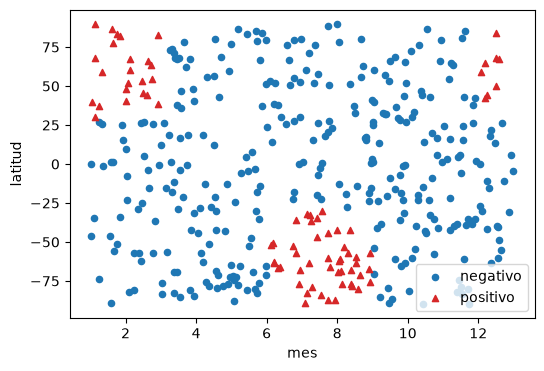

In [2]:
X, y = datos_esqui(m=400)
print("X:", X.shape, " y:", y.shape)
print("Primeros 3 ejemplos:\n", X[:3].round(1), y[:3])
print(f"Positivos: {y.sum()} de {len(y)}")

fig, ax = plt.subplots(figsize=(6, 4))
dibujar_puntos(ax, X, y)
ax.set_xlabel("mes"); ax.set_ylabel("latitud"); ax.legend()
plt.show()

Separamos los datos en **entrenamiento** (para ajustar el modelo) y **prueba** (para medir qué tan bien generaliza). `stratify=y` hace que las dos partes tengan la misma proporción de positivos, lo que es importante cuando una clase es poco frecuente.

In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
print("Entrenamiento:", X_tr.shape, " Prueba:", X_te.shape)

Entrenamiento: (280, 2)  Prueba: (120, 2)


## 1.2 Entrenar un árbol

Todos los modelos de scikit-learn se usan igual:

1. Se crea el modelo con sus hiperparámetros: `modelo = DecisionTreeClassifier(...)`.
2. Se entrena: `modelo.fit(X, y)`.
3. Se predice: `modelo.predict(X_nuevo)`.

Los hiperparámetros más importantes de `DecisionTreeClassifier` son:

| Parámetro | Qué hace | Valor por defecto |
|---|---|---|
| `criterion` | Medida de impureza: `"gini"` o `"entropy"` | `"gini"` |
| `max_depth` | Profundidad máxima | `None` (sin límite) |
| `min_samples_leaf` | Mínimo de ejemplos por hoja | `1` |
| `ccp_alpha` | Intensidad de la poda | `0` (sin poda) |
| `random_state` | Semilla (en empates se escoge al azar) | `None` |

In [4]:
arbol = DecisionTreeClassifier(max_depth=4, random_state=0)
arbol.fit(X_tr, y_tr)
print("Hojas:", arbol.get_n_leaves(), " Profundidad:", arbol.get_depth())

Hojas: 10  Profundidad: 4


## 1.3 Ver el árbol

Una gran ventaja de los árboles es que se pueden leer. Hay dos formas: dibujarlo con `plot_tree` o imprimirlo con `export_text`.

En cada nodo, `plot_tree` muestra la pregunta, la impureza de Gini, el número de ejemplos (`samples`), cuántos hay de cada clase (`value = [negativos, positivos]`) y la clase mayoritaria. Si la respuesta a la pregunta es **verdadera**, se sigue la rama **izquierda**.

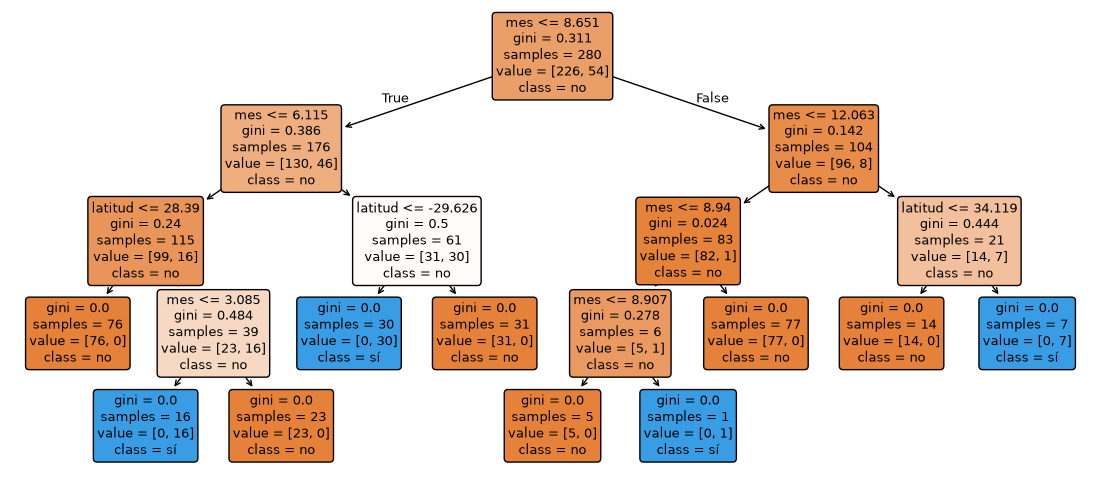

In [5]:
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(arbol, feature_names=["mes", "latitud"], class_names=["no", "sí"], filled=True, rounded=True, ax=ax, fontsize=9)
plt.show()


## 1.4 Predecir

`predict` devuelve la clase y `predict_proba` la proporción de cada clase en la hoja donde cae el punto. Probemos con tres lugares: Canadá en febrero, el Ecuador en julio y Chile en julio.

In [7]:
nuevos = np.array([[2.5, 55],    # Canadá, mediados de febrero
                   [7.5, 0],     # Ecuador, julio
                   [7.5, -40]])  # Chile, julio
print("Clase predicha:", arbol.predict(nuevos))
print("Probabilidades [no, sí]:\n", arbol.predict_proba(nuevos).round(2))

Clase predicha: [1 0 1]
Probabilidades [no, sí]:
 [[0. 1.]
 [1. 0.]
 [0. 1.]]


## 1.5 Evaluar: exactitud y matriz de confusión

La **exactitud** (accuracy) es la fracción de ejemplos bien clasificados. Cuando una clase es poco frecuente puede engañar: aquí solo uno de cada cinco ejemplos es positivo, así que un "modelo" que siempre dice "no se puede esquiar" ya tiene ~80% de exactitud.

La **matriz de confusión** da más información. Las filas son la clase real y las columnas la predicha:

|  | predice "no" | predice "sí" |
|---|---|---|
| **en realidad "no"** | verdaderos negativos | falsos positivos: decimos que se puede esquiar y no se puede |
| **en realidad "sí"** | falsos negativos: nos perdemos un buen día de esquí | verdaderos positivos |

In [ ]:
print(f"Exactitud: entrenamiento {arbol.score(X_tr, y_tr):.1%}, prueba {arbol.score(X_te, y_te):.1%}")
print(f"Siempre decir 'no' tendría exactitud {1 - y_te.mean():.1%} en prueba")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (Xs, ys, nombre) in zip(axs, [(X_tr, y_tr, "Entrenamiento"), (X_te, y_te, "Prueba")]):
    ConfusionMatrixDisplay.from_estimator(arbol, Xs, ys, display_labels=["no", "sí"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

## 1.6 Las regiones del árbol

Como cada pregunta compara una feature con un umbral, las regiones son rectángulos. Probemos varias profundidades. ¿Con qué profundidad el árbol ya encuentra las tres zonas donde se puede esquiar?

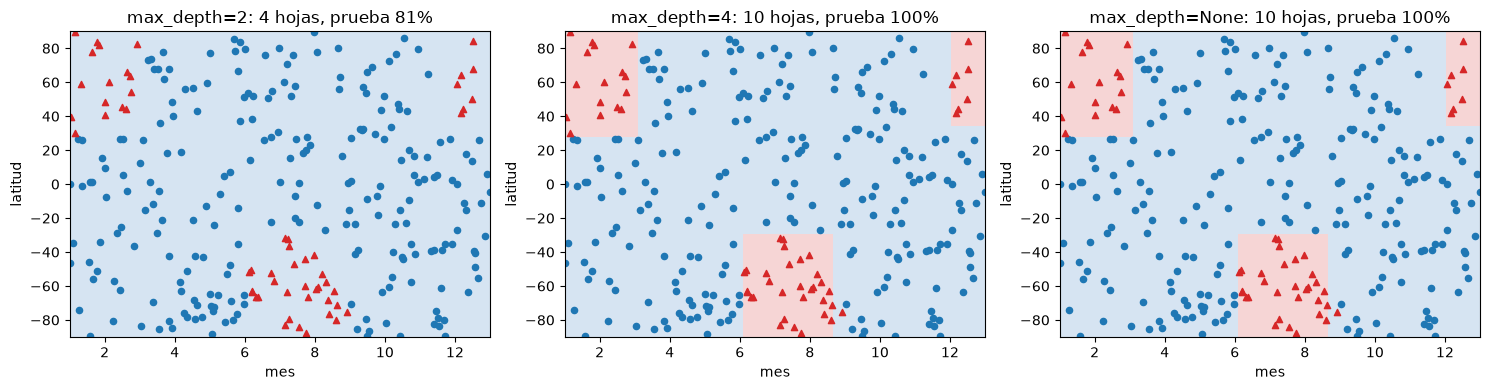

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, prof in zip(axs, [2, 4, None]):
    a = DecisionTreeClassifier(max_depth=prof, random_state=0).fit(X_tr, y_tr)
    dibujar_regiones(ax, a.predict, X_tr, y_tr, (1, 13, -90, 90))
    ax.set_title(f"max_depth={prof}: {a.get_n_leaves()} hojas, prueba {a.score(X_te, y_te):.0%}")
    ax.set_xlabel("mes"); ax.set_ylabel("latitud")
plt.tight_layout()
plt.show()

**Gini vs. entropía.** Como vimos en clase, casi siempre producen el mismo árbol:

In [9]:
for criterio in ["gini", "entropy"]:
    a = DecisionTreeClassifier(criterion=criterio, max_depth=4, random_state=0).fit(X_tr, y_tr)
    print(f"{criterio:8s} raíz: feature {['mes', 'latitud'][a.tree_.feature[0]]} < {a.tree_.threshold[0]:.2f}   prueba: {a.score(X_te, y_te):.1%}")

gini     raíz: feature mes < 8.65   prueba: 100.0%
entropy  raíz: feature mes < 8.94   prueba: 98.3%


---
# Parte 2: Overfitting y cómo escoger la profundidad

Un árbol sin límite clasifica perfecto el entrenamiento, pero memoriza el ruido. Para escoger la profundidad usamos un conjunto de **validación**, separado del de prueba:

- **entrenamiento**: para ajustar el modelo;
- **validación**: para escoger hiperparámetros (como `max_depth`);
- **prueba**: se usa **una sola vez, al final**, para reportar el resultado.

Si escogiéramos `max_depth` mirando el error de prueba, ese error ya no sería una estimación honesta: habríamos ajustado el modelo a esos datos también.

Usamos datos más ruidosos, en forma de dos lunas.

Entrenamiento: 300  Validación: 150  Prueba: 150


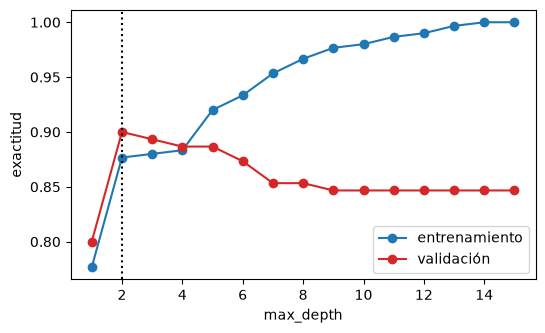

Mejor profundidad según validación: 2
Exactitud de prueba (se mide una sola vez): 86.0%


In [10]:
X_l, y_l = make_moons(n_samples=600, noise=0.35, random_state=2)
X_l_tr, X_l_resto, y_l_tr, y_l_resto = train_test_split(X_l, y_l, test_size=0.5, random_state=0)
X_l_va, X_l_te, y_l_va, y_l_te = train_test_split(X_l_resto, y_l_resto, test_size=0.5, random_state=0)
print("Entrenamiento:", len(y_l_tr), " Validación:", len(y_l_va), " Prueba:", len(y_l_te))

profundidades = range(1, 16)
exact_tr, exact_va = [], []
for prof in profundidades:
    a = DecisionTreeClassifier(max_depth=prof, random_state=0).fit(X_l_tr, y_l_tr)
    exact_tr.append(a.score(X_l_tr, y_l_tr))
    exact_va.append(a.score(X_l_va, y_l_va))

mejor = profundidades[int(np.argmax(exact_va))]
plt.figure(figsize=(6, 3.5))
plt.plot(profundidades, exact_tr, "-o", c=C_NEG, label="entrenamiento")
plt.plot(profundidades, exact_va, "-o", c=C_POS, label="validación")
plt.axvline(mejor, c="k", ls=":")
plt.xlabel("max_depth"); plt.ylabel("exactitud"); plt.legend()
plt.show()

final = DecisionTreeClassifier(max_depth=mejor, random_state=0).fit(X_l_tr, y_l_tr)
print(f"Mejor profundidad según validación: {mejor}")
print(f"Exactitud de prueba (se mide una sola vez): {final.score(X_l_te, y_l_te):.1%}")

Compara la frontera del árbol sin límite con la del árbol escogido por validación:

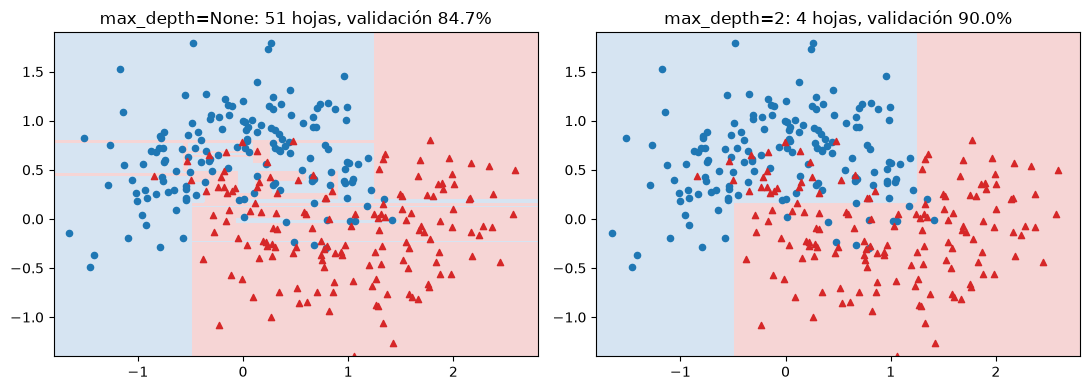

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, prof in zip(axs, [None, mejor]):
    a = DecisionTreeClassifier(max_depth=prof, random_state=0).fit(X_l_tr, y_l_tr)
    dibujar_regiones(ax, a.predict, X_l_tr, y_l_tr, (-1.8, 2.8, -1.4, 1.9))
    ax.set_title(f"max_depth={prof}: {a.get_n_leaves()} hojas, validación {a.score(X_l_va, y_l_va):.1%}")
plt.tight_layout()
plt.show()

---
# Ejercicio 1: Gini y la mejor pregunta (~15 min)

Vas a implementar la parte central del algoritmo que construye un árbol: encontrar la mejor pregunta $x_j < t$ en un nodo. Son tres funciones cortas. Después de cada una hay una celda que la verifica.

### 1a. Impureza de Gini

$$L_\text{Gini}(R) = \sum_c \hat p_c (1 - \hat p_c),$$

donde $\hat p_c$ es la proporción de ejemplos de la clase $c$. La función recibe un arreglo de etiquetas, por ejemplo `np.array([1, 1, 0, 1])`, y devuelve un número. Debe funcionar con cualquier cantidad de clases.

<details><summary>▶ Pista</summary>

`np.unique(y, return_counts=True)` devuelve las clases distintas y cuántas veces aparece cada una. Dividiendo los conteos entre `len(y)` obtienes las proporciones $\hat p_c$. Con numpy no necesitas un `for`: `np.sum(p * (1 - p))`.
</details>

In [ ]:
def gini(y):
    """Impureza de Gini de un arreglo de etiquetas y."""
    # TU CÓDIGO AQUÍ
    _, counts = np.unique(y, return_counts=True)
    # Usando counts, calcula las proporciones de cada clase
   
    # Calcula la impureza de Gini usando la fórmula 1 - sum(p^2) 
    
    

In [ ]:
# Celda de verificación: no la modifiques
def _cerca(a, b):
    return a is not None and abs(float(a) - b) < 1e-9

ej_900 = np.array([1] * 900 + [0] * 100)
verificar(_cerca(gini(ej_900), 0.18), "gini con 900 positivos y 100 negativos = 0.18",
          f"gini con 900 positivos y 100 negativos debería dar 0.18, y da {gini(ej_900)}")
verificar(_cerca(gini(np.array([1, 1, 1])), 0.0), "una región pura tiene impureza 0",
          f"una región pura debería tener impureza 0, y da {gini(np.array([1, 1, 1]))}")
verificar(_cerca(gini(np.array([0, 1])), 0.5), "mitad y mitad = 0.5",
          f"mitad y mitad debería dar 0.5, y da {gini(np.array([0, 1]))}")
verificar(_cerca(gini(np.array([0, 1, 2])), 2 / 3), "funciona con 3 clases (= 2/3)",
          f"con 3 clases igual de frecuentes debería dar 2/3, y da {gini(np.array([0, 1, 2]))}")

### 1b. Ganancia de una división

Una división se representa con un arreglo booleano `izq` del mismo largo que `y`: `izq[i]` es `True` si el ejemplo $i$ va al hijo izquierdo. La ganancia es

$$\text{ganancia} = L(R_p) - \left(\frac{|R_1|}{|R_p|} L(R_1) + \frac{|R_2|}{|R_p|} L(R_2)\right).$$

Puedes suponer que los dos hijos tienen al menos un ejemplo.

<details><summary>▶ Pista</summary>

`y[izq]` son las etiquetas del hijo izquierdo y `y[~izq]` las del derecho (`~` niega un arreglo booleano). `izq.sum()` es el número de ejemplos que van a la izquierda.

Es decir 
```python
izq = y[izq]
der = y[~izq]

# |R_1| = n_izq, |R_2| = n_der, |R_p| = n 
n_izq = izq.sum()
n_der = der.sum()
n = len(y)
```
y la perdida se calcula con `gini(izq)` y `gini(der)`.
</details>

In [ ]:
def ganancia(y, izq):
    """Ganancia de Gini de dividir y en y[izq] y y[~izq]."""
    # TU CÓDIGO AQUÍ
    return None

In [ ]:
# Celda de verificación: no la modifiques
# El ejemplo de las notas: padre (900+, 100-). Los primeros 900 son positivos.
indices = np.arange(1000)
division_A = (indices >= 200)                       # izq: 700 positivos y 100 negativos
division_B = (indices >= 500)                       # izq: 400 positivos y 100 negativos
gA, gB = ganancia(ej_900, division_A), ganancia(ej_900, division_B)
verificar(_cerca(gA, 0.005), "división A: ganancia 0.005", f"la división A debería tener ganancia 0.005, y da {gA}")
verificar(_cerca(gB, 0.02), "división B: ganancia 0.02 (¡cuatro veces la de A!)", f"la división B debería tener ganancia 0.02, y da {gB}")

### 1c. La mejor pregunta

Ahora busca, entre **todas** las features $j$ y **todos** los umbrales $t$, la pregunta $x_j < t$ con mayor ganancia. Devuelve una tupla `(j, t, g)`: la feature, el umbral y la ganancia.

¿Qué umbrales hay que probar? Como vimos en clase, basta con los puntos medios entre valores consecutivos de la feature (ordenados). Por ejemplo, si una feature toma los valores 1, 4 y 6, los umbrales son 2.5 y 5.

<details><summary>▶ Pista 1: la estructura</summary>

```python
mejor = (None, None, -1)
# Por cada feature j
for j in range(X.shape[1]):
    valores = np.unique(X[:, j])                      # ordenados y sin repetidos
    umbrales = (valores[:-1] + valores[1:]) / 2       # puntos medios
    for t in umbrales:
        izq = X[:, j] < t
        g = ...
        if g > mejor[2]:
            mejor = ...
return mejor
```
</details>

In [ ]:
def mejor_division(X, y):
    """Devuelve (j, t, g): la feature, el umbral y la ganancia de la mejor pregunta x_j < t."""
    # TU CÓDIGO AQUÍ
    return None

In [ ]:
# Celda de verificación: no la modifiques
# Comparamos con la raíz que escoge scikit-learn (un árbol de profundidad 1) sobre todos los datos del esquí
tocon = DecisionTreeClassifier(max_depth=1).fit(X, y)
t_sk = tocon.tree_
j_sk, umbral_sk = t_sk.feature[0], t_sk.threshold[0]
n = t_sk.n_node_samples
g_sk = t_sk.impurity[0] - (n[1] * t_sk.impurity[1] + n[2] * t_sk.impurity[2]) / n[0]

resultado = mejor_division(X, y)
if resultado is None:
    print("❌ mejor_division todavía devuelve None")
else:
    j, t, g = resultado
    nombres = ["mes", "latitud"]
    print(f"Tu pregunta:     {nombres[j]} < {t:.3f}  (ganancia {g:.5f})")
    print(f"scikit-learn:    {nombres[j_sk]} <= {umbral_sk:.3f}  (ganancia {g_sk:.5f})")
    verificar(abs(g - g_sk) < 1e-9, "la ganancia coincide con la de scikit-learn",
              "la ganancia no coincide: ¿estás probando todas las features y todos los puntos medios?")
    verificar(j == j_sk and abs(t - umbral_sk) < 1e-6, "y es la misma pregunta",
              "la pregunta es distinta (si la ganancia coincide, puede ser un empate)")

### Tu propio árbol

Con `mejor_division` ya puedes construir un árbol completo: se aplica la función en la raíz, se dividen los datos y se repite en cada hijo. La siguiente celda hace eso usando **tus** funciones (no hace falta modificarla) y compara el resultado con scikit-learn.

Fíjate en la primera pregunta: no es la "natural" de la clase (latitud > 30°). El algoritmo es **codicioso**: escoge la que más ganancia da en este paso, aunque no sea la que un humano haría primero.

In [ ]:
def construir(X, y, profundidad):
    """Árbol como diccionario anidado. Las hojas son la clase mayoritaria."""
    if profundidad == 0 or gini(y) == 0:
        return int(np.round(y.mean()))
    j, t, g = mejor_division(X, y)
    izq = X[:, j] < t
    return {"j": j, "t": t, "izq": construir(X[izq], y[izq], profundidad - 1),
            "der": construir(X[~izq], y[~izq], profundidad - 1)}


def predecir_uno(nodo, x):
    while isinstance(nodo, dict):
        nodo = nodo["izq"] if x[nodo["j"]] < nodo["t"] else nodo["der"]
    return nodo


def imprimir(nodo, nombres, nivel=0, rama=""):
    sangria = "      " * nivel + rama
    if not isinstance(nodo, dict):
        print(sangria + ("se puede esquiar" if nodo == 1 else "no se puede"))
        return
    print(f"{sangria}¿{nombres[nodo['j']]} < {nodo['t']:.2f}?")
    imprimir(nodo["izq"], nombres, nivel + 1, "sí → ")
    imprimir(nodo["der"], nombres, nivel + 1, "no → ")


if mejor_division(X, y) is None:
    raise RuntimeError("Primero completa gini, ganancia y mejor_division (Ejercicio 1a a 1c)")

mi_arbol = construir(X, y, profundidad=3)
imprimir(mi_arbol, ["mes", "latitud"])

mi_pred = np.array([predecir_uno(mi_arbol, x) for x in X])
sk_pred = DecisionTreeClassifier(max_depth=3).fit(X, y).predict(X)
print(f"\nExactitud de entrenamiento: tu árbol {np.mean(mi_pred == y):.1%}, scikit-learn {np.mean(sk_pred == y):.1%}")
print(f"Las predicciones coinciden en {np.mean(mi_pred == sk_pred):.0%} de los ejemplos")

fig, ax = plt.subplots(figsize=(6, 4))
dibujar_regiones(ax, lambda Z: np.array([predecir_uno(mi_arbol, z) for z in Z]), X, y, (1, 13, -90, 90), n=150)
ax.set_title("Tu árbol de profundidad 3"); ax.set_xlabel("mes"); ax.set_ylabel("latitud")
plt.show()

---
# Parte 3: Árboles de regresión

Para regresión se usa `DecisionTreeRegressor`. Cada hoja predice el **promedio** de las etiquetas de sus ejemplos, y la impureza es el error cuadrático medio (`criterion="squared_error"`). Usamos los datos de nieve por mes.

In [ ]:
X_n, y_n = datos_nieve()
reg = DecisionTreeRegressor(max_depth=2).fit(X_n, y_n)
print(export_text(reg, feature_names=["mes"], decimals=1))

xs = np.linspace(1, 13, 500).reshape(-1, 1)
plt.figure(figsize=(6, 3.5))
plt.scatter(X_n, y_n, s=12, c="0.4")
plt.plot(xs, reg.predict(xs), c=C_POS, lw=2)
plt.xlabel("mes"); plt.ylabel("cm de nieve por día")
plt.show()

Comprobemos que el valor de cada hoja es el promedio de sus ejemplos. `apply` devuelve el número de hoja donde cae cada ejemplo:

In [ ]:
hojas = reg.apply(X_n)
for h in np.unique(hojas):
    sel = hojas == h
    print(f"hoja {h}: {sel.sum():2d} ejemplos, promedio {y_n[sel].mean():5.2f}, el árbol predice {reg.predict(X_n[sel])[0]:5.2f}")

---
# Parte 4: Bagging y random forests

**Bagging** entrena $B$ árboles, cada uno con una muestra bootstrap de los datos, y promedia sus predicciones. **Random forest** además sortea, en cada división, un subconjunto de `max_features` features entre las que el árbol puede escoger.

| Parámetro | Bagging (`BaggingClassifier`) | Random forest (`RandomForestClassifier`) |
|---|---|---|
| número de árboles $B$ | `n_estimators` | `n_estimators` |
| modelo base | `estimator=DecisionTreeClassifier()` | siempre árboles |
| features por división | todas | `max_features` (por defecto `"sqrt"`, es decir $\sqrt{d}$) |

Comparemos un árbol, bagging y random forest en los datos de las lunas, a medida que crece $B$. Los conjuntos de validación y prueba de la Parte 2 tienen solo 150 ejemplos, y con tan pocos las exactitudes cambian mucho por azar. Por eso, para estas comparaciones generamos 5000 ejemplos **nuevos** del mismo problema.

In [ ]:
X_l_nuevo, y_l_nuevo = make_moons(n_samples=5000, noise=0.35, random_state=3)

Bs = [1, 2, 5, 10, 20, 50, 100, 200]
exact = {"bagging": [], "random forest": []}
for B in Bs:
    bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=B, random_state=0).fit(X_l_tr, y_l_tr)
    rf = RandomForestClassifier(n_estimators=B, max_features=1, random_state=0).fit(X_l_tr, y_l_tr)
    exact["bagging"].append(bag.score(X_l_nuevo, y_l_nuevo))
    exact["random forest"].append(rf.score(X_l_nuevo, y_l_nuevo))

un_arbol = DecisionTreeClassifier(random_state=0).fit(X_l_tr, y_l_tr).score(X_l_nuevo, y_l_nuevo)
plt.figure(figsize=(6, 3.5))
plt.plot(Bs, exact["bagging"], "-o", c=C_NEG, label="bagging")
plt.plot(Bs, exact["random forest"], "-o", c="#2a9d3a", label="random forest (max_features=1)")
plt.axhline(un_arbol, c="gray", ls="--", label="un árbol")
plt.xscale("log"); plt.xlabel("B (número de árboles)"); plt.ylabel("exactitud (datos nuevos)"); plt.legend()
plt.show()

Fíjate en que la exactitud sube y luego **se estabiliza**: a partir de cierto $B$, más árboles ya no ayudan, pero tampoco producen overfitting. Las pequeñas oscilaciones se deben al azar del bootstrap.

### Importancia de las features

Un random forest también estima qué tan importante es cada feature: cuánto reducen la impureza, en promedio, las divisiones que la usan. Para probarlo, agregamos a los datos del esquí tres features de **puro ruido**. Un buen modelo debería darse cuenta de que no sirven.

In [ ]:
rng = np.random.default_rng(0)
X_ruido = np.c_[X, rng.normal(size=(len(X), 3))]
nombres = ["mes", "latitud", "ruido 1", "ruido 2", "ruido 3"]

rf = RandomForestClassifier(n_estimators=300, random_state=0).fit(X_ruido, y)
orden = np.argsort(rf.feature_importances_)
plt.figure(figsize=(6, 3))
plt.barh(np.array(nombres)[orden], rf.feature_importances_[orden], color=C_NEG)
plt.xlabel("importancia")
plt.show()

---
# Parte 5: Boosting

Boosting entrena los modelos **uno después de otro**, y cada uno corrige los errores de los anteriores. scikit-learn tiene varias versiones:

| Clase | Qué es |
|---|---|
| `AdaBoostClassifier` | AdaBoost: repesa los ejemplos mal clasificados. Por defecto usa tocones (árboles de profundidad 1). |
| `GradientBoostingClassifier` / `Regressor` | Gradient boosting: cada árbol se ajusta a los residuos (gradientes negativos). |
| `HistGradientBoostingClassifier` / `Regressor` | Gradient boosting moderno y rápido, en la línea de XGBoost y LightGBM. Tiene regularización $L_2$ de las hojas (`l2_regularization`, la $\lambda$ de XGBoost) y early stopping. |

En la industria es muy común usar la librería `xgboost`, cuya clase `XGBClassifier` tiene una interfaz casi idéntica (`n_estimators`, `learning_rate`, `max_depth`, `reg_lambda`, ...). Aquí usaremos `HistGradientBoostingClassifier`, que viene con scikit-learn.

Veamos AdaBoost en las lunas. `staged_score` da la exactitud después de cada ronda. Un solo tocón es un modelo muy débil, pero en pocas rondas la combinación supera a un árbol completo:

In [ ]:
ada = AdaBoostClassifier(n_estimators=300, random_state=0).fit(X_l_tr, y_l_tr)
exact_ada = list(ada.staged_score(X_l_nuevo, y_l_nuevo))

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(exact_ada) + 1), exact_ada, c=C_POS, label="AdaBoost con tocones")
plt.axhline(un_arbol, c="gray", ls="--", label="un árbol completo")
plt.xlabel("ronda"); plt.ylabel("exactitud (datos nuevos)"); plt.legend()
plt.show()
print(f"Un tocón solo: {exact_ada[0]:.1%}   Después de 300 rondas: {exact_ada[-1]:.1%}")

Y `HistGradientBoostingClassifier`. Sus parámetros principales son:

| Parámetro | En las notas | Por defecto |
|---|---|---|
| `max_iter` | número de árboles $B$ | 100 |
| `learning_rate` | tasa de aprendizaje $\nu$ | 0.1 |
| `max_depth` / `max_leaf_nodes` | tamaño de cada árbol | `None` / 31 |
| `l2_regularization` | $\lambda$ de XGBoost | 0 |
| `early_stopping` | parar cuando la validación deja de mejorar | `"auto"` (activo si hay más de 10 000 ejemplos) |

In [ ]:
hgb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, max_depth=3, random_state=0).fit(X_l_tr, y_l_tr)
print(f"Exactitud en datos nuevos: {hgb.score(X_l_nuevo, y_l_nuevo):.1%}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
dibujar_regiones(axs[0], ada.predict, X_l_tr, y_l_tr, (-1.8, 2.8, -1.4, 1.9))
axs[0].set_title(f"AdaBoost (300 tocones): {ada.score(X_l_nuevo, y_l_nuevo):.1%}")
dibujar_regiones(axs[1], hgb.predict, X_l_tr, y_l_tr, (-1.8, 2.8, -1.4, 1.9))
axs[1].set_title(f"HistGradientBoosting: {hgb.score(X_l_nuevo, y_l_nuevo):.1%}")
plt.tight_layout()
plt.show()

---
# Ejercicio 2: Competencia

Vas a competir con tres modelos sobre el mismo problema: **un árbol**, **un random forest** y **gradient boosting**. Tu trabajo es ajustar sus hiperparámetros para alcanzar las metas.

**Los datos.** Es un problema clásico del libro *The Elements of Statistical Learning*. Hay 10 features con distribución normal estándar, y la clase es positiva cuando $x_1^2 + x_2^2 + \dots + x_{10}^2$ es mayor que cierto umbral, es decir, cuando el punto está lejos del origen.

**Las reglas**
1. Solo puedes cambiar los hiperparámetros en las celdas marcadas.
2. Para comparar modelos usas el error de **validación**.
3. El conjunto de **prueba** se usa una sola vez, al final, en la última celda.

In [ ]:
X_h, y_h = make_hastie_10_2(n_samples=12000, random_state=1)
y_h = (y_h > 0).astype(int)
X_h_tr, y_h_tr = X_h[:2000], y_h[:2000]          # entrenamiento
X_h_va, y_h_va = X_h[2000:4000], y_h[2000:4000]  # validación
X_h_te, y_h_te = X_h[4000:], y_h[4000:]          # prueba (¡no la toques hasta el final!)
print(f"Entrenamiento {len(y_h_tr)}, validación {len(y_h_va)}, prueba {len(y_h_te)}. Positivos: {y_h.mean():.0%}")

resultados = {}

def evaluar(nombre, modelo, meta):
    modelo.fit(X_h_tr, y_h_tr)
    error = 1 - modelo.score(X_h_va, y_h_va)
    resultados[nombre] = (modelo, error)
    marca = "🎯 ¡meta alcanzada!" if error < meta else f"(meta: menos de {meta:.1%})"
    print(f"{nombre}: error de validación {error:.1%}  {marca}")

### Modelo 1: un árbol. Meta: error de validación < 24.5%

<details><summary>▶ Pista</summary>

El árbol sin límite sobreajusta. ¿Qué regularización de la Parte 2 podrías usar? Prueba `max_depth` y también `min_samples_leaf` (por ejemplo, 10, 20, 50).
</details>

In [12]:
# Cambia los hiperparámetros
modelo_arbol = DecisionTreeClassifier(
    max_depth=50,
    min_samples_leaf=4,
    random_state=0,
)
evaluar("árbol", modelo_arbol, meta=0.245)

NameError: name 'evaluar' is not defined

### Modelo 2: random forest. Meta: error de validación < 13.5%

<details><summary>▶ Pista</summary>

Más árboles no hacen daño, pero el parámetro que más importa aquí es `max_features`. Recuerda: random forest funciona mejor cuando los árboles están **poco correlacionados**. ¿Con qué valor de `max_features` serán más distintos entre sí? Prueba valores entre 1 y 10.
</details>

In [ ]:
# Cambia los hiperparámetros
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    max_features=1,
    min_samples_leaf=2,
    random_state=0,
)
evaluar("random forest", modelo_rf, meta=0.135)

### Modelo 3: gradient boosting. Meta: error de validación < 9%

<details><summary>▶ Pista 1</summary>

La clase depende de una **suma** de términos, uno por feature: $x_1^2 + \dots + x_{10}^2$. En las notas vimos que a los árboles les cuesta capturar estructuras aditivas, pero que boosting **suma** árboles. ¿Qué tan profundo tiene que ser cada árbol para representar un solo término $x_j^2$?
</details>

<details><summary>▶ Pista 2</summary>

Prueba `max_depth=1` (tocones). Con árboles tan pequeños hacen falta muchos más (`max_iter` de 500 o 1000) y quizás un `learning_rate` más grande.
</details>

In [ ]:
# Cambia los hiperparámetros
modelo_gb = HistGradientBoostingClassifier(
    max_iter=500,
    learning_rate=0.4,
    max_depth=1,
    l2_regularization=0.0,
    early_stopping=False,
    random_state=0,
)
evaluar("gradient boosting", modelo_gb, meta=0.09)

### Resultado final

Cuando estés conforme con tus tres modelos, ejecuta esta celda **una sola vez**. Evalúa cada modelo en el conjunto de prueba, que ninguno ha visto.

In [ ]:
print(f"{'modelo':20s} {'validación':>12s} {'prueba':>10s}")
for nombre, (modelo, error_va) in resultados.items():
    error_te = 1 - modelo.score(X_h_te, y_h_te)
    print(f"{nombre:20s} {error_va:12.1%} {error_te:10.1%}")

### Preguntas

Responde brevemente en esta celda (doble clic para editar):

1. ¿Qué modelo ganó? ¿Los errores de prueba se parecen a los de validación? ¿Por qué deberían parecerse?
2. ¿Por qué un solo árbol es tan malo en este problema?
3. ¿Qué hiperparámetro del random forest tuvo más efecto?
4. ¿Por qué funcionan tan bien los tocones en boosting para este problema en particular?

*Tus respuestas:*